# One drop on a single ETFE membrane — step by step (v5)


Model: Toyoda & Takahashi (2013), Eq. (1) for one membrane between two semi-infinite air ducts,
the same 5x5 system as the supervisor's MATLAB code and Cell 3 of *copy 2*. No damping.
Bending stiffness is optional: `wave_model` in Step 0 chooses Toyoda (tension only) or the
dispersion curve (tension + bending).
Time convention $e^{-i\omega t}$. Side 0 ($z<0$) is the side the drop comes from, side 1 ($z>0$) the
other side: in Eq. (1) the load $q$ has the sign of $p_0$, so it pushes towards $+z$.

## Step 0 — Parameters
Same values as Cell 1 of *copy 2*, except the stress, σ = 0.9 MPa (`M_250` of *c_f_graph.ipynb*), and
the drop point: the impact point `1_1` of the recordings, 9 cm and 13 cm from the top-left corner.
$E$ and $\nu$ come from *c_f_graph.ipynb* (configuration `M_250`, the 250 µm membrane), and are
used only when `wave_model = 'dispersion'`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3})
dB = lambda x: 10*np.log10(np.where(x > 0, x, np.nan))     # zeros -> gaps in the plots

a, b           = 1.46, 1.29        # membrane size [m]
rho_m, h       = 1760, 0.25e-3     # density [kg/m3], thickness [m]
stress         = 0.9e6             # in-plane stress sigma [Pa] (M_250 in c_f_graph)
T              = stress * h        # tension = stress x thickness [N/m]
E_young, nu    = 2.1e9, 0.45       # Young's modulus [Pa], Poisson ratio (M_250 in c_f_graph)
wave_model     = 'toyoda'          # 'toyoda': tension only | 'dispersion': tension + bending
rho_air, c_air = 1.225, 343        # air
r_drop, v_drop = 0.0025, 5.7       # drop radius [m], impact speed [m/s]
rho_water      = 1000
x0_ratio, y0_ratio = 0.061, 0.101  # where the drop hits: 9 cm, 13 cm from the top-left corner
n_modes        = 80                # 70 in copy 2; up to 9.3 kHz modes up to m = 80 radiate
f_vec          = np.linspace(10, 9300, 4700)
df             = f_vec[1] - f_vec[0]

mh  = rho_m * h                                        # surface density [kg/m2]
c_m = np.sqrt(T / mh)                                  # wave speed with tension only [m/s] = sqrt(stress/rho_m)
D   = E_young*h**3 / (12*(1 - nu**2))                  # bending stiffness [N.m]
D_model = D if wave_model == 'dispersion' else 0.0     # what the model uses from here on
print(f"stress = {stress/1e6:.2f} MPa   T = stress x h = {T:.1f} N/m   rho_m h = {mh:.3f} kg/m2")
print(f"c_m = {c_m:.2f} m/s   c_air/c_m = {c_air/c_m:.1f}   D = {D:.3e} N.m   wave_model = '{wave_model}'")

stress = 0.90 MPa   T = stress x h = 225.0 N/m   rho_m h = 0.440 kg/m2
c_m = 22.61 m/s   c_air/c_m = 15.2   D = 3.429e-03 N.m   wave_model = 'toyoda'


## Step 1a — Wave speed on the membrane: Toyoda or dispersion curve
Free waves $e^{i(kx-\omega t)}$ on a tensioned plate obey $\rho h\,\omega^2 = T k^2 + D k^4$.
Toyoda keeps only the tension ($D=0$), so the phase speed $c=\omega/k$ is $c_m$ at every frequency.
With bending, $c$ rises with frequency:
$c^2=\big(\sigma+\sqrt{\sigma^2+4\rho_m\omega^2D/h}\big)/2\rho_m$, $\sigma=T/h$ — the formula of
`bending_wave_speed_tension` in *c_f_graph.ipynb*. Energy travels at the group speed
$c_g=d\omega/dk=(Tk+2Dk^3)/(\rho h\,\omega)$.

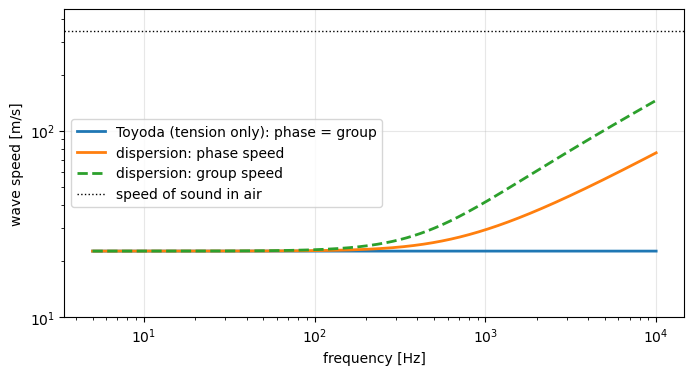

f =    10 Hz   Toyoda c = 22.61 m/s   dispersion c = 22.61 m/s, c_g = 22.62 m/s
f =   100 Hz   Toyoda c = 22.61 m/s   dispersion c = 22.74 m/s, c_g = 23.01 m/s
f =  1000 Hz   Toyoda c = 22.61 m/s   dispersion c = 29.44 m/s, c_g = 41.50 m/s
f =  9300 Hz   Toyoda c = 22.61 m/s   dispersion c = 73.62 m/s, c_g = 140.30 m/s
bending = tension at 1304 Hz (c = 32.0 m/s);  c reaches c_air at 212 kHz


In [4]:
def wave_speeds(f, D_):
    """Phase and group speed of free waves [m/s]. D_ = 0 gives Toyoda."""
    w = 2*np.pi*np.asarray(f, float)
    c = np.sqrt((T/h + np.sqrt((T/h)**2 + 4*rho_m*w**2*D_/h)) / (2*rho_m))
    k = w / c
    return c, (T*k + 2*D_*k**3) / (mh*w)

f_plot = np.logspace(np.log10(5), 4, 2000)
c_toy, cg_toy = wave_speeds(f_plot, 0.0)
c_dis, cg_dis = wave_speeds(f_plot, D)
plt.loglog(f_plot, c_toy, lw=2, label='Toyoda (tension only): phase = group')
plt.loglog(f_plot, c_dis, lw=2, label='dispersion: phase speed')
plt.loglog(f_plot, cg_dis, '--', lw=2, label='dispersion: group speed')
plt.axhline(c_air, c='k', ls=':', lw=1, label='speed of sound in air')
plt.xlabel('frequency [Hz]'); plt.ylabel('wave speed [m/s]'); plt.ylim(10, 450)
plt.legend(); plt.show()

for f in [10, 100, 1000, 9300]:
    (ct, _), (cd, cg) = wave_speeds(f, 0.0), wave_speeds(f, D)
    print(f"f = {f:5d} Hz   Toyoda c = {ct:5.2f} m/s   dispersion c = {cd:5.2f} m/s, c_g = {cg:5.2f} m/s")
f_eq  = T*np.sqrt(2/(D*mh)) / (2*np.pi)                                 # T k^2 = D k^4
f_coi = c_air**2*np.sqrt(mh/D)*np.sqrt(1 - (c_m/c_air)**2) / (2*np.pi)  # c = c_air
print(f"bending = tension at {f_eq:.0f} Hz (c = {np.sqrt(2)*c_m:.1f} m/s);  c reaches c_air at {f_coi/1e3:.0f} kHz")

## Step 1b — One mode, without air
$k_{mn}^2=(m\pi/a)^2+(n\pi/b)^2$. The resonance in vacuum is $f_{mn}=\sqrt{(Tk_{mn}^2+Dk_{mn}^4)/\rho h}\,/2\pi$
($=c_m k_{mn}/2\pi$ for Toyoda). The duct mode with the same shape starts to carry sound at its cut-on
$f_c=c_{air}k_{mn}/2\pi$, so $f_c/f_{mn}=c_{air}/c(f_{mn})$.

In [5]:
m, n = 1, 1
kmn2_ = (m*np.pi/a)**2 + (n*np.pi/b)**2
f_res = np.sqrt((T*kmn2_ + D_model*kmn2_**2) / mh) / (2*np.pi)
f_cut = c_air * np.sqrt(kmn2_) / (2*np.pi)
print(f"mode ({m},{n}):  k_mn = {np.sqrt(kmn2_):.3f} rad/m   f_res = {f_res:.2f} Hz   "
      f"f_cut = {f_cut:.1f} Hz   f_cut/f_res = {f_cut/f_res:.2f}")
print(f"phase speed at f_res = {2*np.pi*f_res/np.sqrt(kmn2_):.2f} m/s   (wave_model = '{wave_model}')")

mode (1,1):  k_mn = 3.250 rad/m   f_res = 11.70 Hz   f_cut = 177.4 Hz   f_cut/f_res = 15.17
phase speed at f_res = 22.61 m/s   (wave_model = 'toyoda')


Higher modes, both models side by side:

In [6]:
for m_, n_ in [(1, 1), (10, 10), (40, 40), (80, 80)]:
    k2 = (m_*np.pi/a)**2 + (n_*np.pi/b)**2
    f_t = np.sqrt(T*k2 / mh) / (2*np.pi)
    f_d = np.sqrt((T*k2 + D*k2**2) / mh) / (2*np.pi)
    print(f"({m_:2d},{n_:2d})   f_res Toyoda {f_t:7.1f} Hz   dispersion {f_d:7.1f} Hz   "
          f"c there {2*np.pi*f_d/np.sqrt(k2):5.1f} m/s   f_cut {c_air*np.sqrt(k2)/(2*np.pi):7.0f} Hz")

( 1, 1)   f_res Toyoda    11.7 Hz   dispersion    11.7 Hz   c there  22.6 m/s   f_cut     177 Hz
(10,10)   f_res Toyoda   117.0 Hz   dispersion   117.9 Hz   c there  22.8 m/s   f_cut    1774 Hz
(40,40)   f_res Toyoda   467.8 Hz   dispersion   524.6 Hz   c there  25.4 m/s   f_cut    7096 Hz
(80,80)   f_res Toyoda   935.7 Hz   dispersion  1333.1 Hz   c there  32.2 m/s   f_cut   14192 Hz


## Step 2 — The air in front of this mode
$k_z=\sqrt{-\gamma^2-k_{mn}^2}=\sqrt{k^2-k_{mn}^2}$ with $\gamma=-ik$. Below cut-on $k_z$ is
imaginary: the field decays over $1/\mathrm{Im}\,k_z$ metres and carries no power.
The paper takes the root with $\mathrm{Im}\,k_z\ge0$ (below Eq. 8). `np.sqrt` alone does not guarantee
this: on Python 3.14 the sign of a zero imaginary part changes and the root flips, so the second line
enforces it.

In [7]:
for f in [100.0, 1000.0]:
    gamma = -1j * 2*np.pi*f / c_air
    kz = np.sqrt(-gamma**2 - kmn2_)
    kz = np.where(kz.imag < 0, -kz, kz)            # Im kz >= 0: evanescent fields decay
    state = "propagates" if kz.real > 0 else f"evanescent, decays over {100/kz.imag:.1f} cm"
    print(f"f = {f:6.0f} Hz   kz = {kz:.3f} rad/m   -> {state}")

f =    100 Hz   kz = 0.000+2.684j rad/m   -> evanescent, decays over 37.3 cm
f =   1000 Hz   kz = 18.028+0.000j rad/m   -> propagates


## Step 3 — The 5x5 system for this mode at one frequency
Unknowns $P_0^+, P_0^-, P_1^+, P_1^-, W_1$, with $p=P^+e^{ik_zz}+P^-e^{-ik_zz}$ and
$v=K(-P^++P^-)$, $K=ik_z/(\gamma Z)$. Same rows as Cell 3 of *copy 2*, for unit modal load $Q=1$ N/m².

In [8]:
f = 1000.0
w = 2*np.pi*f
gamma = -1j * w / c_air
Z = rho_air * c_air
kz = np.sqrt(-gamma**2 - kmn2_)
kz = np.where(kz.imag < 0, -kz, kz)                # Im kz >= 0 (Step 2)
K = 1j * kz / (gamma * Z)
beta1 = T*kmn2_ + D_model*kmn2_**2 - mh*w**2   # membrane stiffness - mass
Q = 1.0

A = np.array([[ 1,  0,  0,  0,  0    ],        # P0+ = 0  : nothing comes in on side 0
              [ 0,  0,  0,  1,  0    ],        # P1- = 0  : nothing comes in on side 1
              [-1, -1,  1,  1,  beta1],        # Eq. 1    : beta1 W1 + p1 - p0 = Q
              [-K,  K,  K, -K,  0    ],        # Eq. 10a  : v0 = v1
              [-K,  K,  0,  0,  1j*w ]],       # Eq. 10b  : v0 = -i w W1
             dtype=complex)
B = np.array([0, 0, Q, 0, 0], dtype=complex)
X = np.linalg.solve(A, B)
for name, x in zip(['P0+', 'P0-', 'P1+', 'P1-', 'W1 '], X):
    print(f"{name} = {x: .5e}")

P0+ =  0.00000e+00+0.00000e+00j
P0- = -4.35562e-02-1.41000e-01j
P1+ =  4.35562e-02+1.41000e-01j
P1- =  0.00000e+00+0.00000e+00j
W1  = -5.25611e-08+1.62366e-08j


## Step 4 — The same answer in closed form
Eliminating the pressures: $W_1=Q/N$, $N=\beta_1+2Z_r$, $Z_r=\omega\gamma Z/k_z$ (MATLAB `WZ`),
$P_1^+=Z_rW_1$, $P_0^-=-Z_rW_1$.

In [9]:
Zr = w * gamma * Z / kz
N  = beta1 + 2*Zr
W1 = Q / N
print(f"closed form   W1 = {W1: .5e}   P1+ = {Zr*W1: .5e}   P0- = {-Zr*W1: .5e}")
print(f"5x5 solve     W1 = {X[4]: .5e}   P1+ = {X[2]: .5e}   P0- = {X[1]: .5e}")

closed form   W1 = -5.25611e-08+1.62366e-08j   P1+ =  4.35562e-02+1.41000e-01j   P0- = -4.35562e-02-1.41000e-01j
5x5 solve     W1 = -5.25611e-08+1.62366e-08j   P1+ =  4.35562e-02+1.41000e-01j   P0- = -4.35562e-02-1.41000e-01j


## Step 5 — One mode over frequency
The closed form of Step 4 in a small function, used from here on. Watch where $|W_1|$ peaks: below
cut-on $Z_r$ is real, so the air only adds mass ($2\rho_{air}/|k_z|$) and lowers the resonance.

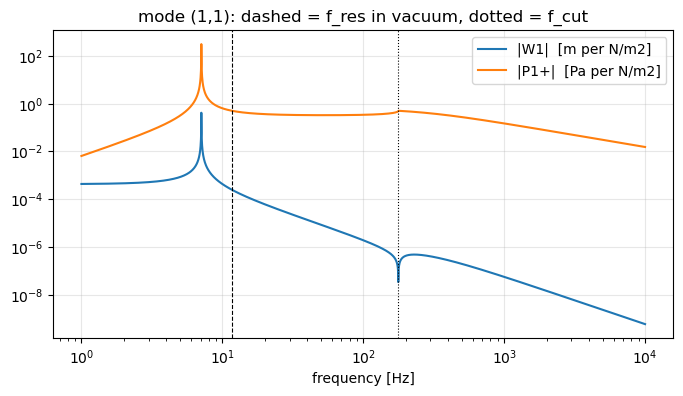

|W1| peaks at 7.09 Hz  (f_res without air: 11.70 Hz)
phase speed of the mode at the peak = 13.72 m/s  (free wave without air: 22.61 m/s)


In [10]:
def mode_response(f, kmn2_, D_=D_model):
    """Step 4 for unit modal load Q = 1. Works for one or many modes."""
    w = 2*np.pi*f
    gamma = -1j * w / c_air
    kz = np.sqrt(-gamma**2 - kmn2_)
    kz = np.where(kz.imag < 0, -kz, kz)            # Im kz >= 0 (Step 2)
    Zr = w * gamma * rho_air*c_air / kz
    W1 = 1.0 / (T*kmn2_ + D_*kmn2_**2 - mh*w**2 + 2*Zr)
    return W1, Zr*W1, kz                       # W1, P1+, kz

f_log = np.logspace(0, 4, 3000)
W1, P1, kz = mode_response(f_log, kmn2_)
plt.loglog(f_log, abs(W1), label='|W1|  [m per N/m2]')
plt.loglog(f_log, abs(P1), label='|P1+|  [Pa per N/m2]')
plt.axvline(f_res, c='k', ls='--', lw=0.8); plt.axvline(f_cut, c='k', ls=':', lw=0.8)
plt.xlabel('frequency [Hz]'); plt.title(f'mode ({m},{n}): dashed = f_res in vacuum, dotted = f_cut')
plt.legend(); plt.show()
f_pk = f_log[np.argmax(abs(W1))]
print(f"|W1| peaks at {f_pk:.2f} Hz  (f_res without air: {f_res:.2f} Hz)")
print(f"phase speed of the mode at the peak = {2*np.pi*f_pk/np.sqrt(kmn2_):.2f} m/s  "
      f"(free wave without air: {wave_speeds(f_pk, D_model)[0]:.2f} m/s)")

## Step 6 — Power of one mode
Radiated into side 1, Eq. (24) for one mode: $\Pi_1=\frac{ab}{8\rho_{air}\omega}\mathrm{Re}(k_z)|P_1^+|^2$.
Put in by the load: $\Pi_{in}=\tfrac12\mathrm{Re}(Q^*v)\tfrac{ab}{4}$ with $v=-i\omega W_1$.
Without damping all of it must leave through the two faces: $\Pi_{in}=2\Pi_1$.

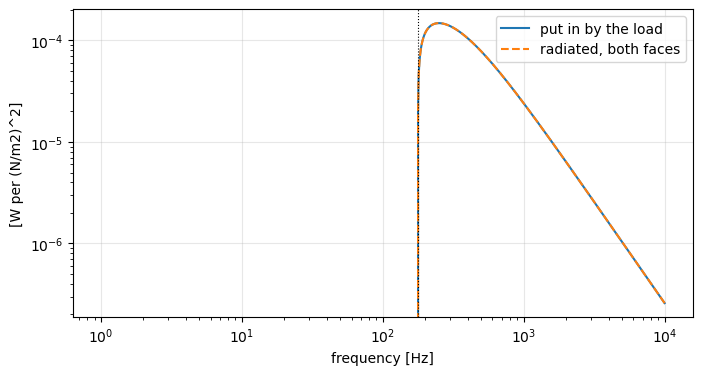

largest |Pi_in - 2 Pi_1| / max(Pi_in) = 7.3e-16
largest Pi_1 below cut-on            = 0.0e+00 W


In [11]:
w = 2*np.pi*f_log
Pi_1  = a*b/(8*rho_air*w) * kz.real * abs(P1)**2
Pi_in = 0.5 * np.real(-1j*w*W1) * a*b/4
plt.loglog(f_log, Pi_in, label='put in by the load')
plt.loglog(f_log, 2*Pi_1, '--', label='radiated, both faces')
plt.axvline(f_cut, c='k', ls=':', lw=0.8)
plt.xlabel('frequency [Hz]'); plt.ylabel('[W per (N/m2)^2]'); plt.legend(); plt.show()
print(f"largest |Pi_in - 2 Pi_1| / max(Pi_in) = {np.max(abs(Pi_in - 2*Pi_1))/Pi_in.max():.1e}")
print(f"largest Pi_1 below cut-on            = {Pi_1[f_log < f_cut].max():.1e} W")

## Step 7 — All modes, and the drop point
A point force $F$ at $(x_0,y_0)$ gives every mode the load $Q_{mn}=\frac{4}{ab}F\varphi_{mn}(x_0,y_0)$,
with $\varphi_{mn}=\sin(m\pi x/a)\sin(n\pi y/b)$. Modes with a nodal line through the drop point
get nothing.

6400 modes, drop at x0/a = 0.061, y0/b = 0.101
modes not excited (phi = 0): 0


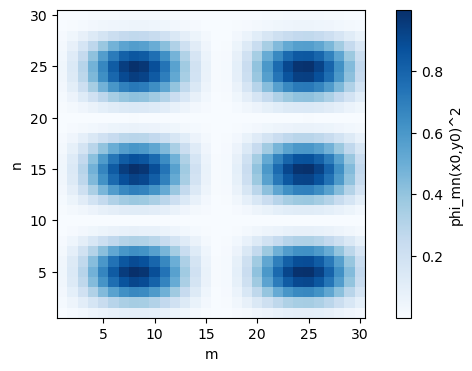

In [12]:
mm, nn = np.meshgrid(np.arange(1, n_modes+1), np.arange(1, n_modes+1), indexing='ij')
mm, nn = mm.ravel(), nn.ravel()                       # every (m, n) pair in two flat lists
kmn2_all = (mm*np.pi/a)**2 + (nn*np.pi/b)**2
phi0 = np.sin(mm*np.pi*x0_ratio) * np.sin(nn*np.pi*y0_ratio)
Q_mn = 4/(a*b) * phi0                                  # load per 1 N.s of drop impulse
print(f"{mm.size} modes, drop at x0/a = {x0_ratio}, y0/b = {y0_ratio}")
print(f"modes not excited (phi = 0): {np.sum(abs(phi0) < 1e-12)}")
M = 30                                                 # show the first 30 x 30 modes
plt.imshow((phi0**2).reshape(n_modes, n_modes)[:M, :M].T, origin='lower', cmap='Blues',
           extent=[0.5, M+0.5, 0.5, M+0.5])
plt.colorbar(label='phi_mn(x0,y0)^2'); plt.xlabel('m'); plt.ylabel('n'); plt.grid(False); plt.show()

## Step 8 — Sum over modes for a unit impulse (1 N·s)
Mode energies add (the duct modes are orthogonal). The factor 4 turns Eq. (24), a time-averaged
power of amplitudes, into the one-sided energy per Hz of a transient: ×2 undoes the ½ of the
harmonic average, ×2 folds the negative frequencies (Step 9 checks this second ×2).

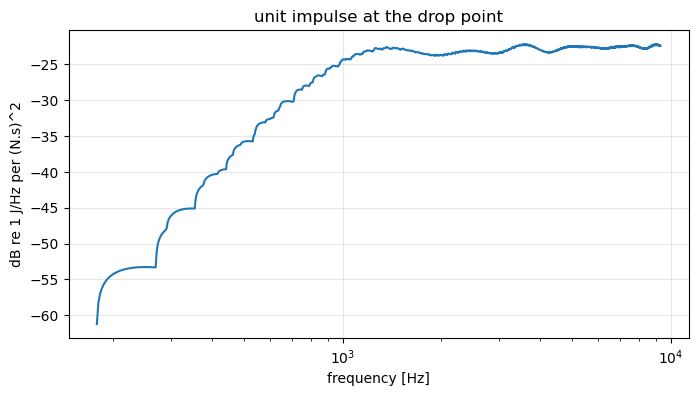

energy for 1 N.s, 10-9300 Hz: 4.4432e+01 J


In [13]:
def radiated_energy(f_vec, kmn2_, Q_mn, D_=D_model):
    """Energy per Hz radiated by ONE face [J/Hz] for modal loads Q_mn."""
    E = np.zeros(f_vec.size)
    for i, f in enumerate(f_vec):
        W1, P1, kz = mode_response(f, kmn2_, D_)
        E[i] = 4 * np.sum(a*b/(8*rho_air*2*np.pi*f) * kz.real * abs(P1*Q_mn)**2)
    return E

E_unit = radiated_energy(f_vec, kmn2_all, Q_mn)
plt.semilogx(f_vec, dB(E_unit))
plt.xlabel('frequency [Hz]'); plt.ylabel('dB re 1 J/Hz per (N.s)^2'); plt.title('unit impulse at the drop point'); plt.show()
print(f"energy for 1 N.s, {f_vec[0]:.0f}-{f_vec[-1]:.0f} Hz: {np.sum(E_unit)*df:.4e} J")

## Step 9 — The drop force
Eqs. (18)–(21): $F(t)=a_F-b_Ft$ for $0\le t\le T_d$ and zero before and after the impact: a sawtooth.
Its transform has a closed form, $F(\omega)=a_FT_d\,g(\omega T_d)$ with $g(x)=(1-e^{-ix})/x^2-i/x$. At
$f\to0$ it is the momentum $mv$. The cell also checks the closed form against the FFT route of Cell 2
(same sampling and zero padding), and Parseval: $\int F^2dt = 2\int_0^\infty|F|^2df$.

peak force 0.6379 N   duration 1.1696 ms   1/T_d = 855 Hz
|F| at 1 Hz = 3.73064e-04 N.s    momentum m v = 3.73064e-04 N.s
FFT vs closed form, 10-9300 Hz: largest difference 0.001 dB
integral F^2 dt = 1.586616e-04    one-sided sum |F|^2 df = 1.586761e-04


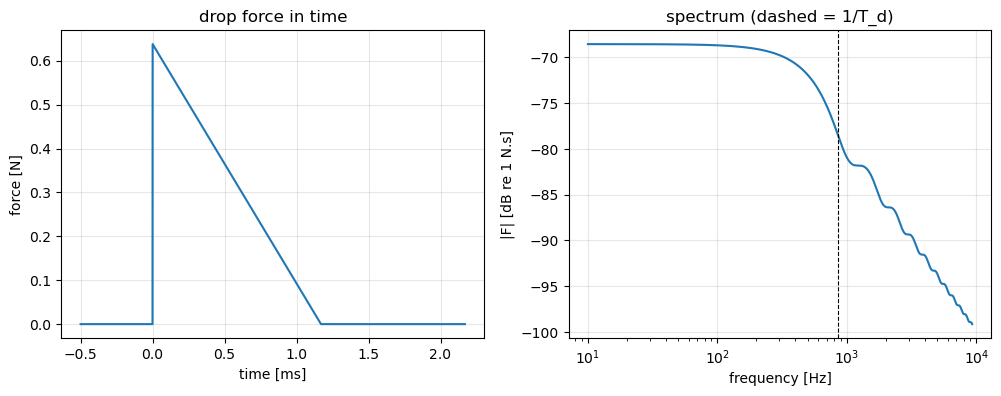

In [14]:
a_F = rho_water*np.pi*r_drop**2*v_drop**2          # peak force [N]
b_F = 3*rho_water*np.pi*r_drop*v_drop**3/8         # slope [N/s]
T_d = 8*r_drop/(3*v_drop)                          # duration [s]
m_drop = rho_water*4/3*np.pi*r_drop**3

def drop_force(f):
    x = 2*np.pi*np.asarray(f, float)*T_d
    return a_F*T_d*((1 - np.exp(-1j*x))/x**2 - 1j/x)

t = np.linspace(0, T_d, 16384)                     # FFT route of Cell 2
F_t = a_F - b_F*t
dt = t[1] - t[0]
F_fft = np.fft.fft(np.concatenate([F_t, np.zeros(20*t.size)])) * dt
f_fft = np.arange(F_fft.size) / (F_fft.size*dt)
band = (f_fft >= f_vec[0]) & (f_fft <= f_vec[-1])
half = F_fft.size//2                                               # bins 0 .. half-1 are f >= 0
one_sided = abs(F_fft[0])**2 + 2*np.sum(abs(F_fft[1:half])**2)    # 0 Hz counted once

print(f"peak force {a_F:.4f} N   duration {T_d*1e3:.4f} ms   1/T_d = {1/T_d:.0f} Hz")
print(f"|F| at 1 Hz = {abs(drop_force(1.0)):.5e} N.s    momentum m v = {m_drop*v_drop:.5e} N.s")
print(f"FFT vs closed form, {f_vec[0]:.0f}-{f_vec[-1]:.0f} Hz: largest difference "
      f"{np.max(abs(20*np.log10(abs(F_fft[band])/abs(drop_force(f_fft[band]))))):.3f} dB")
print(f"integral F^2 dt = {a_F**2*T_d/3:.6e}    one-sided sum |F|^2 df = {one_sided*(f_fft[1]-f_fft[0]):.6e}")

t_ms = np.linspace(-0.5, T_d*1e3 + 1.0, 3000)                      # 0.5 ms before to 1 ms after
F_plot = np.where((t_ms >= 0) & (t_ms <= T_d*1e3), a_F - b_F*t_ms*1e-3, 0.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t_ms, F_plot)
ax1.set_xlabel('time [ms]'); ax1.set_ylabel('force [N]'); ax1.set_title('drop force in time')
ax2.semilogx(f_vec, 20*np.log10(abs(drop_force(f_vec))))
ax2.axvline(1/T_d, c='k', ls='--', lw=0.8)
ax2.set_xlabel('frequency [Hz]'); ax2.set_ylabel('|F| [dB re 1 N.s]'); ax2.set_title('spectrum (dashed = 1/T_d)')
plt.show()

## Step 10 — One drop
$E_{drop}(f)=|F(f)|^2\,E_{unit}(f)$ [J/Hz], one face.

sound energy of one drop, one face: 6.0458e-08 J
kinetic energy of the drop:         1.0632e-03 J   (ratio 5.69e-05)


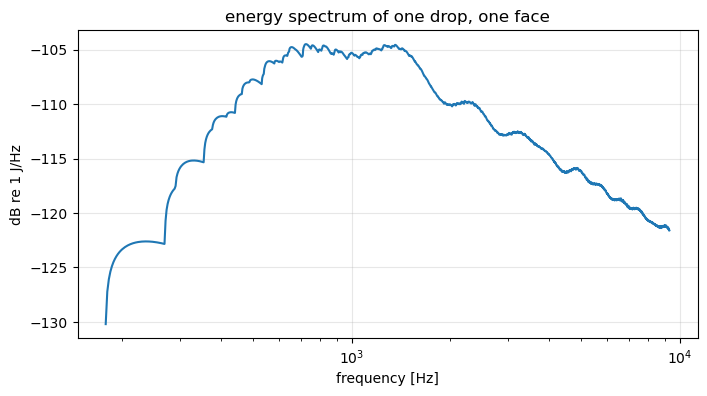

In [15]:
E_drop = abs(drop_force(f_vec))**2 * E_unit
E_tot  = np.sum(E_drop) * df
E_kin  = 0.5*m_drop*v_drop**2
print(f"sound energy of one drop, one face: {E_tot:.4e} J")
print(f"kinetic energy of the drop:         {E_kin:.4e} J   (ratio {E_tot/E_kin:.2e})")
plt.semilogx(f_vec, dB(E_drop))
plt.xlabel('frequency [Hz]'); plt.ylabel('dB re 1 J/Hz'); plt.title('energy spectrum of one drop, one face'); plt.show()

## Step 11 — The recorded drops: whole spectrum
Files `../Wav files/Membrane/<row>_<col>/Ch <n>/*.wav` (16 bit, 10 drops per channel). They start
about 12 ms before the impact, so the window starts at the beginning of the file. Per file:
$X$ = FFT × $\Delta t$ of the pressure, and the one-sided energy spectral density $2|X|^2$ in
Pa²·s/Hz, the same quantity as the model in Steps 13–14.

Your settings, all at the top of the cell:
* `cal_dB` — the RMS of the calibrator recording in dBFS (RMS relative to full scale = 1), one
  number or a dict `{channel: value}`; `None` = not calibrated. `cal_SPL` — the calibrator level
  (94 dB). From these the cell computes the calibration in Pa per full scale,
  $\mathrm{cal}=20\,\mu\mathrm{Pa}\cdot10^{\,\mathrm{cal\_SPL}/20}\,/\,10^{\,\mathrm{cal\_dB}/20}$.
  1 dB more in `cal_dB` moves every level 1 dB down.
* `smooth` — fractional-octave smoothing of each file's spectrum, e.g. `1/3`, `1/12`, `1/24`;
  `None` = no smoothing.
* `channels`, `pos`, `win`.

The curve is the **mean of the dB levels** over the files; the grey band is ± 1 **standard
deviation** over the files at each frequency.

In [16]:
from pathlib import Path
from scipy.io import wavfile

pos      = '1_1'                  # row_col of the impact point
channels = [5]                   # microphones to include
win      = 6                   # window from the start of the file [s]
cal_dB   = -3.86556               # RMS of the calibrator recording [dBFS] (or {channel: value}); None = not calibrated
cal_SPL  = 94.0                   # calibrator level [dB re 20 uPa]
smooth   = None         # fractional-octave smoothing, e.g. 1/3, 1/12; None = no smoothing
n_fft    = 2**19
xlim_plot = (20, 10000)

def smooth_oct(f, E, frac):
    # mean of E over f*2^(-frac/2) ... f*2^(+frac/2); frac = None: E unchanged
    if not frac:
        return E
    c  = np.concatenate([[0.0], np.cumsum(E)])
    lo = np.searchsorted(f, f*2**(-frac/2))
    hi = np.searchsorted(f, f*2**(frac/2), side='right')
    return (c[hi] - c[lo]) / np.maximum(hi - lo, 1)

cal = {}                                       # Pa per full scale, per channel
L_files = []
for ch in channels:
    rms_dB  = cal_dB[ch] if isinstance(cal_dB, dict) else cal_dB
    cal[ch] = 1.0 if rms_dB is None else 20e-6*10**(cal_SPL/20) / 10**(rms_dB/20)
    for path in sorted(Path('../Wav files/Membrane').glob(f'{pos}/Ch {ch}/*.wav')):
        fs, x = wavfile.read(path)
        X     = np.fft.rfft(cal[ch] * x[:int(win*fs)] / 32768, n_fft) / fs    # [Pa.s]
        f_rec = np.fft.rfftfreq(n_fft, 1/fs)
        L_files.append(dB(smooth_oct(f_rec, 2*abs(X)**2, smooth) / 20e-6**2))
L_mean = np.mean(L_files, axis=0)              # mean of the dB levels
smooth_txt = f'1/{round(1/smooth)} octave' if smooth else 'none'
L_std  = np.std(L_files, axis=0)               # standard deviation over the files [dB]

plt.semilogx(f_rec, L_mean, c='k', lw=1, label=f'mean of {len(L_files)} files')
plt.fill_between(f_rec, L_mean - L_std, L_mean + L_std, color='0.75', label='± 1 standard deviation')
plt.xlim(xlim_plot); plt.xlabel('frequency [Hz]'); plt.ylabel('dB re (20 uPa)^2 s/Hz')
plt.title(f'recorded, position {pos}, channels {channels}, smoothing {smooth_txt}'); plt.legend(); plt.show()
sel = (f_rec >= 100) & (f_rec <= 9300)
print(f"{len(L_files)} files, fs = {fs} Hz, window {win*1e3:.0f} ms, resolution {f_rec[1]:.2f} Hz")
print("calibration: " + ", ".join(f"Ch {k}: {v:.4f} Pa per full scale ({20*np.log10(v):+.2f} dB)" for k, v in cal.items())
      + ("" if cal_dB is not None else "   (cal_dB = None: NOT calibrated)"))
print(f"standard deviation over the files, median over 100-9300 Hz: {np.median(L_std[sel]):.1f} dB")

C:\Users\verme\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\verme\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\verme\anaconda3\Lib\site-packages\numpy\_core\_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\verme\anaconda3\Lib\site-packages\numpy\_core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\verme\anaconda3\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


NameError: name 'f_rec' is not defined

## Step 12 — The model on the recording
The radiated energy of Step 10, but for the impact point of the recordings, smoothed in the same
way (`smooth` of Step 11). The impact point is the drop point of
Step 0. The model is energy through one face [J/Hz], the recording is pressure at a
microphone, so the two differ by one level shift: `offset_dB`. Set it yourself, or leave `None` to fit
it (median difference over 250–4000 Hz).

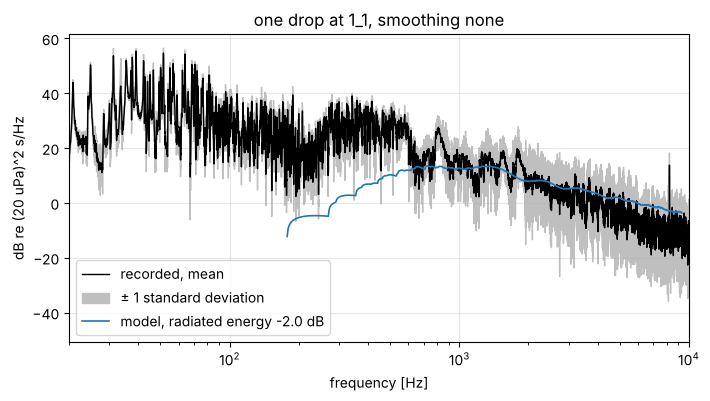

  177- 500 Hz   median of recorded - (model -2.0 dB): +23.9 dB
  500-2000 Hz   median of recorded - (model -2.0 dB):  +2.6 dB
 2000-9300 Hz   median of recorded - (model -2.0 dB):  -5.1 dB


In [15]:
offset_dB = None                    # your own value in dB, or None = fitted on 250-4000 Hz


x_imp, y_imp = x0_ratio, y0_ratio                                  # the impact point is the drop point of Step 0
phi_imp = np.sin(mm*np.pi*x_imp) * np.sin(nn*np.pi*y_imp)
E_imp   = abs(drop_force(f_vec))**2 * radiated_energy(f_vec, kmn2_all, 4/(a*b)*phi_imp)
L_mod   = dB(smooth_oct(f_vec, E_imp, smooth) / 1e-12)         # dB re 1 pJ/Hz
L_rec_m = np.interp(f_vec, f_rec, L_mean)                      # recording on the model grid
if offset_dB is None:
    fit = (f_vec >= 250) & (f_vec <= 4000)
    offset_dB = np.nanmedian(L_rec_m[fit] - L_mod[fit])

plt.semilogx(f_rec, L_mean, c='k', lw=1, label='recorded, mean')
plt.fill_between(f_rec, L_mean - L_std, L_mean + L_std, color='0.75', label='± 1 standard deviation')
plt.semilogx(f_vec, L_mod + offset_dB, lw=1.2, label=f'model, radiated energy {offset_dB:+.1f} dB')
plt.xlim(xlim_plot); plt.xlabel('frequency [Hz]'); plt.ylabel('dB re (20 uPa)^2 s/Hz')
plt.title(f'one drop at {pos}, smoothing {smooth_txt}'); plt.legend(); plt.show()
for lo, hi in [(177, 500), (500, 2000), (2000, 9300)]:
    s_ = (f_vec >= lo) & (f_vec <= hi)
    print(f"{lo:5d}-{hi:4d} Hz   median of recorded - (model {offset_dB:+.1f} dB): {np.nanmedian(L_rec_m[s_] - L_mod[s_] - offset_dB):+5.1f} dB")

## Step 13 — The field close to the membrane (imaginary $k_z$)
Below its cut-on a mode has $k_z=i|k_z|$. Its pressure $P_1^+e^{ik_zz}=P_1^+e^{-|k_z|z}$ dies out away
from the membrane, and $p/v=\rho_{air}\omega/k_z$ is imaginary: pressure and velocity are 90° apart, so
the mode carries no power. Eq. (24) and $E(f)$ leave these modes out, but a microphone close to the
membrane hears them. Here: the pressure of one drop at distance $z$ above the drop point, split into
propagating modes (real $k_z$) and evanescent modes (imaginary $k_z$). Side 0 is the mirror image
($P_0^-=-P_1^+$). The duct has no spreading, so only the comparison between the parts matters, not
the absolute level.

Without damping, every mode below its cut-on has a resonance with nothing to limit it ($N$ is real
there). Close to the membrane these show as spikes whose height depends on the frequency grid, so
the print gives **medians over frequency**, not integrals.

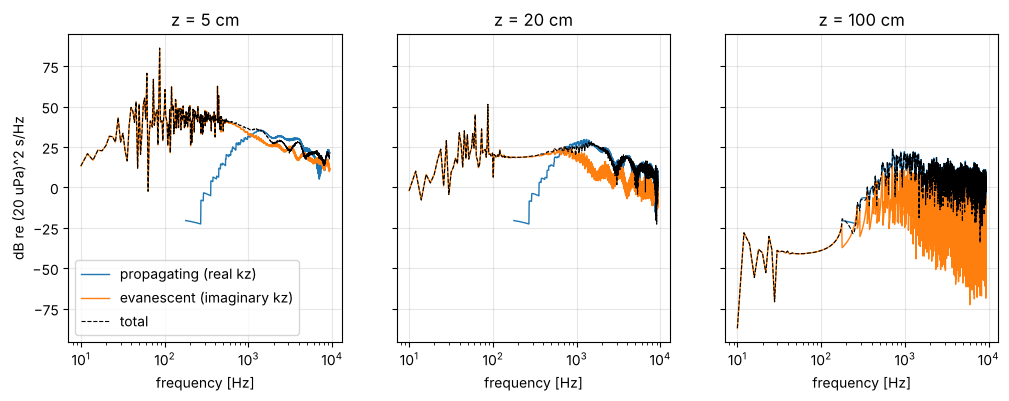

median of evanescent - propagating [dB]       177- 500 Hz  500-2000 Hz 2000-9300 Hz   | below 177 Hz (evanescent only)
z =   5 cm                                       +46.1         -3.6         -4.6   |  41.2 dB re (20 uPa)^2 s/Hz
z =  20 cm                                       +23.0        -11.8        -11.6   |  18.9 dB re (20 uPa)^2 s/Hz
z = 100 cm                                       -13.1        -25.2        -33.8   | -38.8 dB re (20 uPa)^2 s/Hz


In [16]:
z_list = [0.05, 0.2, 1.0]                              # distance from the membrane [m]
F_f    = drop_force(f_vec)
p_prop = np.zeros((len(z_list), f_vec.size), complex)  # propagating modes [Pa.s]
p_evan = np.zeros((len(z_list), f_vec.size), complex)  # evanescent modes [Pa.s]
for i, f in enumerate(f_vec):
    W1, P1, kz = mode_response(f, kmn2_all)
    p_z0 = F_f[i] * Q_mn * P1 * phi0                   # every mode at z = 0, above the drop point
    prop = kz.real > 0
    for j, z in enumerate(z_list):
        p_z = p_z0 * np.exp(1j*kz*z)                   # travels, or decays as exp(-|kz| z)
        p_prop[j, i], p_evan[j, i] = p_z[prop].sum(), p_z[~prop].sum()

L = lambda p: dB(2*abs(p)**2 / 20e-6**2)               # one-sided, dB re (20 uPa)^2 s/Hz
fig, axs = plt.subplots(1, len(z_list), figsize=(12, 4), sharey=True)
for ax, z, pp, pe in zip(axs, z_list, p_prop, p_evan):
    ax.semilogx(f_vec, L(pp), lw=1, label='propagating (real kz)')
    ax.semilogx(f_vec, L(pe), lw=1, label='evanescent (imaginary kz)')
    ax.semilogx(f_vec, L(pp + pe), 'k--', lw=0.8, label='total')
    ax.set_title(f'z = {z*100:.0f} cm'); ax.set_xlabel('frequency [Hz]')
axs[0].set_ylabel('dB re (20 uPa)^2 s/Hz'); axs[0].legend(); plt.show()

f_cut1 = c_air*np.sqrt(kmn2_all.min()) / (2*np.pi)             # first cut-on, mode (1,1)
ranges = [(f_cut1, 500), (500, 2000), (2000, f_vec[-1])]
print("median of evanescent - propagating [dB]     " + "".join(f"{lo:5.0f}-{hi:4.0f} Hz" for lo, hi in ranges)
      + f"   | below {f_cut1:.0f} Hz (evanescent only)")
for j, z in enumerate(z_list):
    d = [np.median((L(p_evan[j]) - L(p_prop[j]))[(f_vec > lo) & (f_vec <= hi)]) for lo, hi in ranges]
    print(f"z = {z*100:3.0f} cm                               " + "".join(f"{x:+13.1f}" for x in d)
          + f"   | {np.median(L(p_evan[j, f_vec < f_cut1])):5.1f} dB re (20 uPa)^2 s/Hz")

The same curves, one figure per distance, each zoomed on its own levels (between the 1st and 99.5th
percentile of the three curves, so single spikes do not set the scale).

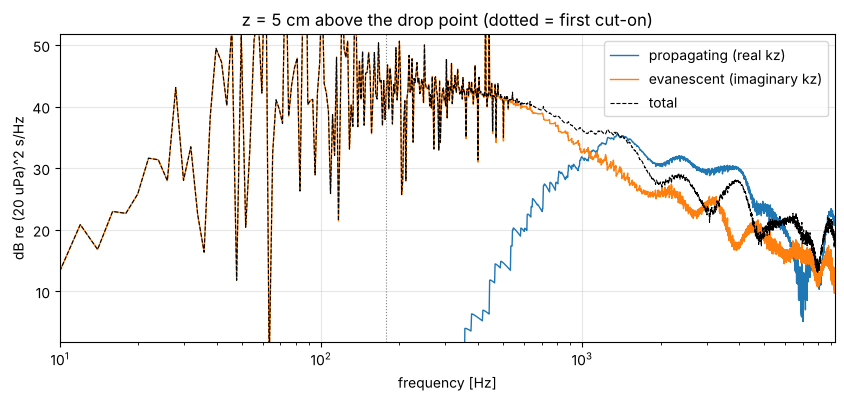

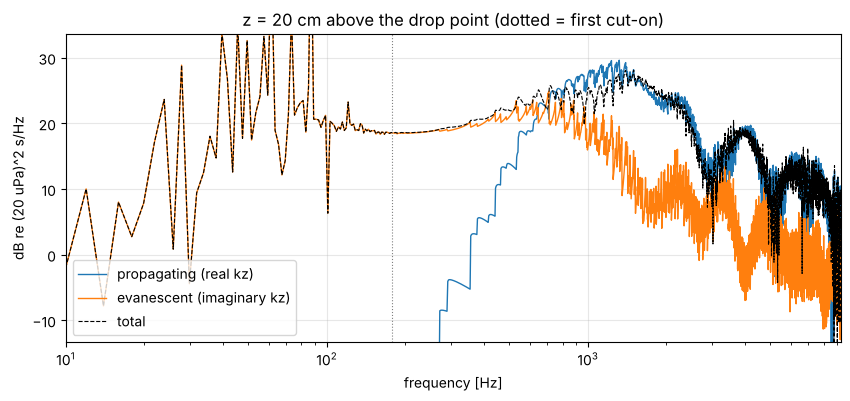

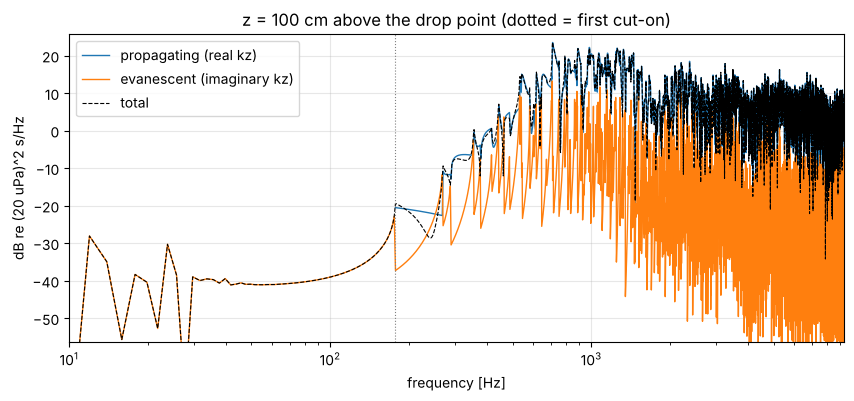

In [17]:
for z, pp, pe in zip(z_list, p_prop, p_evan):
    curves = [L(pp), L(pe), L(pp + pe)]
    lo, hi = np.nanpercentile(np.concatenate(curves), [1, 99.5])
    plt.figure(figsize=(10, 4))
    plt.semilogx(f_vec, curves[0], lw=1, label='propagating (real kz)')
    plt.semilogx(f_vec, curves[1], lw=1, label='evanescent (imaginary kz)')
    plt.semilogx(f_vec, curves[2], 'k--', lw=0.8, label='total')
    plt.axvline(f_cut1, c='0.5', ls=':', lw=0.8)
    plt.xlim(f_vec[0], f_vec[-1]); plt.ylim(lo - 5, hi + 5)
    plt.xlabel('frequency [Hz]'); plt.ylabel('dB re (20 uPa)^2 s/Hz')
    plt.title(f'z = {z*100:.0f} cm above the drop point (dotted = first cut-on)'); plt.legend(); plt.show()

## Step 14 — The recording on the total field at a chosen distance
The total pressure (propagating + evanescent modes, added as complex numbers, Step 13) at the
microphone, for the drop at the impact point of Step 12, next to the recording of Step 11 — both in
dB re (20 µPa)²·s/Hz, with the same smoothing and **no offset**. The level comparison is only
meaningful when `cal_dB` in Step 11 is set. Remember that the duct does not spread the propagating
modes, so the model level does not fall with distance as in free field.

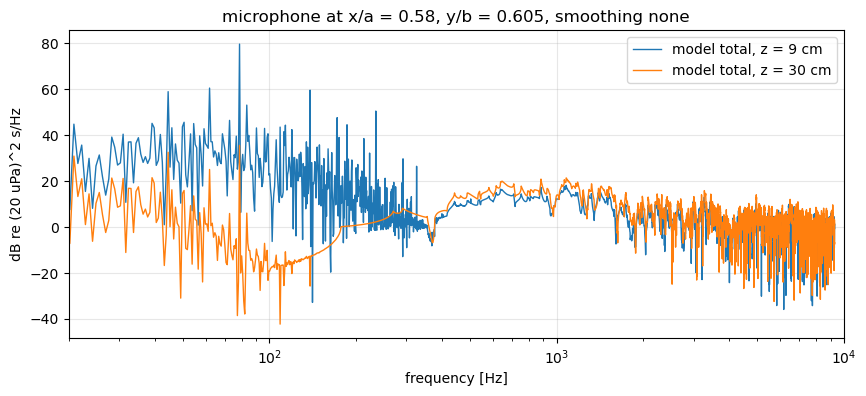

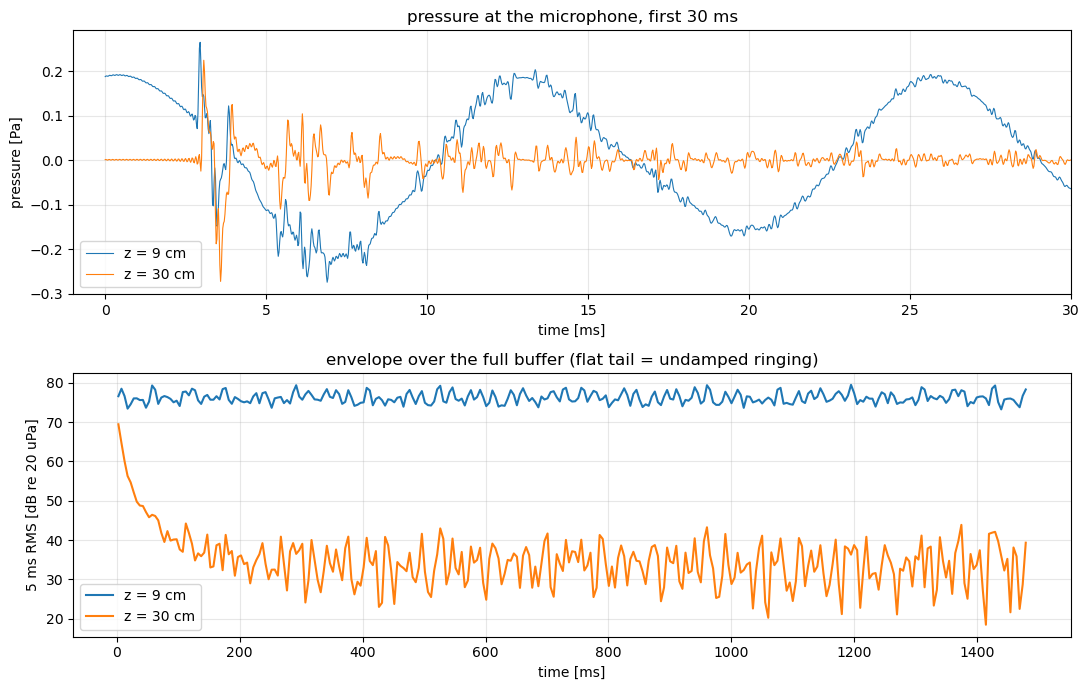

z =   9 cm   RMS [Pa]   0-20 ms: 1.36e-01   20-100 ms: 1.28e-01   0.5-1.4 s: 1.33e-01   (tail/start = 0.98)
z =  30 cm   RMS [Pa]   0-20 ms: 3.63e-02   20-100 ms: 4.93e-03   0.5-1.4 s: 1.24e-03   (tail/start = 0.03)
wrote majid_raindrop_z09cm.wav
wrote majid_raindrop_z30cm.wav


In [17]:
# Step 14 (no recordings needed): model pressure at the microphone,
# spectrum + time domain + wav export, for several mic distances z

from scipy.io import wavfile

x_mic, y_mic = 0.84/a, 0.78/b          # microphone 84 cm, 78 cm from the corner
z_list  = [0.09, 0.30]                 # mic distances from the membrane [m]
smooth  = None                         # fractional-octave smoothing: 1/3, 1/12, ...; None = none
xlim_plot = (20, 10000)

fs_out = 44100
N_out  = 2**16                         # 1.49 s buffer, df = 0.67 Hz (long enough to see ringing)
f_out  = np.fft.rfftfreq(N_out, 1/fs_out)
idx    = np.where((f_out >= f_vec[0]) & (f_out <= f_vec[-1]))[0]      # model band 10-9300 Hz

dB = lambda x: 10*np.log10(np.where(x > 0, x, np.nan))
def smooth_oct(f, E, frac):
    if not frac:
        return E
    c  = np.concatenate([[0.0], np.cumsum(E)])
    lo = np.searchsorted(f, f*2**(-frac/2))
    hi = np.searchsorted(f, f*2**(frac/2), side='right')
    return (c[hi] - c[lo]) / np.maximum(hi - lo, 1)

# Modal factors (recomputed here: Step 12 defines phi_imp, but that cell needs the recordings)
phi_imp = np.sin(mm*np.pi*x0_ratio) * np.sin(nn*np.pi*y0_ratio)
phi_mic = np.sin(mm*np.pi*x_mic)    * np.sin(nn*np.pi*y_mic)
Q_imp   = 4/(a*b) * phi_imp

# Drop force on this grid. conj(): drop_force has the e^{-iwt} *kernel* (only |F| mattered in
# the energy plots); for a waveform with the e^{-iwt} membrane model we need the conjugate.
F_out = np.conj(drop_force(f_out[idx]))

P_out = np.zeros((len(z_list), f_out.size), complex)      # pressure spectrum [Pa.s]
for j, i in enumerate(idx):
    W1, P1, kz = mode_response(f_out[i], kmn2_all)
    base = F_out[j] * Q_imp * P1 * phi_mic                # all modes at z = 0
    for q, z in enumerate(z_list):
        P_out[q, i] = np.sum(base * np.exp(1j*kz*z))      # propagate / decay to the mic

# ---- Spectrum: one-sided energy spectral density, dB re (20 uPa)^2 s/Hz (same as before)
smooth_txt = f'1/{round(1/smooth)} octave' if smooth else 'none'
plt.figure(figsize=(10, 4))
for q, z in enumerate(z_list):
    L = dB(smooth_oct(f_out, 2*abs(P_out[q])**2, smooth) / 20e-6**2)
    plt.semilogx(f_out[1:], L[1:], lw=1, label=f'model total, z = {z*100:.0f} cm')
plt.xlim(xlim_plot); plt.xlabel('frequency [Hz]'); plt.ylabel('dB re (20 uPa)^2 s/Hz')
plt.title(f'microphone at x/a = {x_mic:.2f}, y/b = {y_mic:.3f}, smoothing {smooth_txt}')
plt.legend(); plt.show()

# ---- Time domain. e^{-iwt} convention -> conj() before irfft; *fs_out converts Pa.s -> Pa
p_t  = [np.fft.irfft(np.conj(P_out[q])*fs_out, n=N_out) for q in range(len(z_list))]
t_s  = np.arange(N_out) / fs_out

fig, axs = plt.subplots(2, 1, figsize=(11, 7))
win  = int(0.005*fs_out)                                  # 5 ms RMS windows
nwin = N_out // win
for q, z in enumerate(z_list):
    axs[0].plot(t_s*1e3, p_t[q], lw=0.8, label=f'z = {z*100:.0f} cm')
    env = np.sqrt(np.mean(p_t[q][:nwin*win].reshape(nwin, win)**2, axis=1))
    axs[1].plot((np.arange(nwin)+0.5)*win/fs_out*1e3, 20*np.log10(env/20e-6 + 1e-30), label=f'z = {z*100:.0f} cm')
axs[0].set_xlim(-1, 30); axs[0].set_xlabel('time [ms]'); axs[0].set_ylabel('pressure [Pa]')
axs[0].set_title('pressure at the microphone, first 30 ms'); axs[0].legend()
axs[1].set_xlabel('time [ms]'); axs[1].set_ylabel('5 ms RMS [dB re 20 uPa]')
axs[1].set_title('envelope over the full buffer (flat tail = undamped ringing)'); axs[1].legend()
plt.tight_layout(); plt.show()

for q, z in enumerate(z_list):
    r = lambda lo, hi: np.sqrt(np.mean(p_t[q][(t_s >= lo) & (t_s < hi)]**2))
    print(f"z = {z*100:3.0f} cm   RMS [Pa]   0-20 ms: {r(0,.02):.2e}   20-100 ms: {r(.02,.1):.2e}   "
          f"0.5-1.4 s: {r(.5,1.4):.2e}   (tail/start = {r(.5,1.4)/r(0,.02):.2f})")

# ---- Export (each normalised to its own peak with headroom, so you hear the character)
for q, z in enumerate(z_list):
    y = p_t[q] / (np.max(np.abs(p_t[q])) + 1e-30)
    name = f"majid_raindrop_z{int(round(z*100)):02d}cm.wav"
    wavfile.write(name, fs_out, (0.9*y*32767).astype(np.int16))
    print("wrote", name)

## Step 14 was changed with Claude
